# Red Cedar — Regression

This notebook follows the Quick Start's steps for **regression**: instead of a class, the model predicts a number. It trains a quantum machine learning model on samples whose target value is known, and then uses it to predict the values of samples whose target is not yet known.

The steps:
1. Train a regression model on a CSV file
2. Measure the model on its test rows
3. Predict values using the trained model
4. Check the predicted values

The data is the Energy Efficiency dataset (UCI). Each row is a building design: 8 measurements of its shape (the *features*: compactness, surface, wall and roof area, height, orientation and glazing) and its heating load (the *target*, a number from 6 to 43). The notebook uses two files in the `data/` folder:
- `energy_train.csv`: 614 buildings with their heating load, to train the model.
- `energy_to_predict.csv`: 154 other buildings, with the measurements only, for the trained model to predict.

**Known issue in this release:** regression does not work well yet. In the run saved here, the model predicts about the same value for every building, near the top of the range, and its predictions are further off than simply guessing the average heating load of the training buildings (section 4). The steps below are the ones to use; the results are expected to improve in a later release.

All computation happens on the Red Cedar server; this notebook sends requests and shows the results. The [User Guide](https://coherent-computing.github.io/redcedar/user_guide/) describes every SDK function.

In [1]:
# The two data files described above
train_file = "data/energy_train.csv"            # 614 buildings with their heating load
to_predict_file = "data/energy_to_predict.csv"  # 154 buildings, measurements only

In [2]:
import redcedar

# Connect to a Red Cedar server: the one in REDCEDAR_URL (with the key in REDCEDAR_API_KEY)
# if those are set, otherwise the one on this machine, http://127.0.0.1:8002
client = redcedar.connect()
print(client.status())

# To choose a server in the code instead:
# client = redcedar.connect(url="https://your-server/api", api_key="your-key")

# Developers with the Red Cedar source installed (pip install -e) can use local mode,
# which runs Red Cedar in this process, with no server:
# client = redcedar.connect(local=True)

{'ok': True, 'server_version': '0.92-18-g1706a0dc-dirty', 'sdk_version': '0.93.0'}


## 1. Train a regression model

Training works as in the Quick Start: it imprints the patterns in your data onto a quantum circuit, optimizing its parameters so that the quantum state it produces best links each sample's features to its target value.

**How a number is predicted.** The circuit encodes the target as a binary number on a few of its qubits (`num_qubits_target`, 2 by default). The predicted value is the average of that number over the measured outcomes, scaled to the range of the training targets, so predictions stay between the smallest and largest value seen in training.

`training.run()` detects regression from a target with fractional numbers; `task="regression"` says so explicitly, and is needed for a target of whole numbers. Here 6 qubits and 2 layers, with a fixed `seed` so the run can be repeated.

After each layer the server reports the **test loss** on the rows it set aside from the file (20%), which the model does not train on: how far the predictions on those rows are from the actual values, on a scale from 0 to 1 (lower is better). Regression has no accuracy.

More in the User Guide: [Classification or Regression](https://coherent-computing.github.io/redcedar/user_guide/#classification-or-regression), [Settings](https://coherent-computing.github.io/redcedar/user_guide/#settings).

In [3]:
result = client.training.run(train_file, task="regression", verbose=True, settings={
    "num_qubits": 6,
    "min_layers": 1,
    "max_layers": 2,
    "seed": 123,
})

train_id = result["train_id"]
print(f"\nModel ID: {train_id}")
print(f"Training time: {result['elapsed_seconds']}s")
for layer, v in result["validation"].items():
    print(f"Layer {layer}: test loss {v['test_loss']:.4f}")

  [  5%] Layer 1/2 ...........
  Layer 1: test loss 0.5276
  [ 50%] Layer 2/2 .................
  Layer 2: test loss 0.5297
  [100%] Done.

Model ID: a3b7c739-fbbd-4a05-9b31-601181d293d8
Training time: 84.6s
Layer 1: test loss 0.5276
Layer 2: test loss 0.5297


## 2. Measure the model on its test rows

The test loss is on a scale from 0 to 1. `training.evaluate()` scores the model again on the same test rows and adds the **mean absolute error**: how far off the predictions are on average, in the target's own units (here, heating load). More in the User Guide: [Evaluating a Model](https://coherent-computing.github.io/redcedar/user_guide/#evaluating-a-model).

In [4]:
evaluation = client.training.evaluate(train_id)
print(f"Mean absolute error {evaluation['mean_absolute_error']:.2f} on {evaluation['test_samples']} test rows "
      f"(loss {evaluation['overall_loss']:.4f})")

Mean absolute error 19.55 on 123 test rows (loss 0.5297)


## 3. Predict values using the trained model

Now we apply the trained model to the 154 buildings in `energy_to_predict.csv`, whose heating load is not yet known. For each one the model predicts a value.

`inference.run()` matches the file's columns to the training file's by name (using a trained model on samples it hasn't seen is called *inference*), and `output=` writes each building with its predicted value to `energy_predicted.csv`. More in the User Guide: [Predictions](https://coherent-computing.github.io/redcedar/user_guide/#predictions).

  [100%] Done.

Predicted heating load for 154 buildings, from 42.3 to 42.7

The first 10:
  Sample  Predicted
       1      42.45
       2      42.65
       3      42.39
       4      42.65
       5      42.58
       6      42.58
       7      42.58
       8      42.51
       9      42.45
      10      42.65


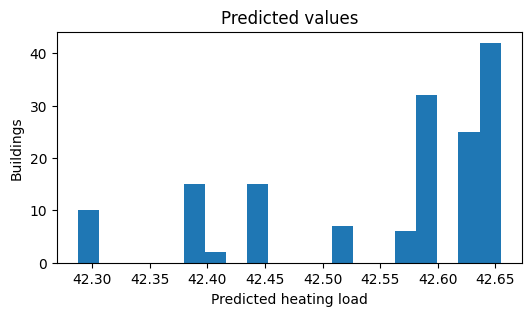

In [5]:
import matplotlib.pyplot as plt

def plot_predicted_values(values):
    """Print the range and the first 10 predicted values; plot how the values are spread."""
    print(f"\nPredicted heating load for {len(values)} buildings, from {min(values):.1f} to {max(values):.1f}")
    print("\nThe first 10:")
    print(f"  {'Sample':>6}  {'Predicted':>9}")
    for i, v in enumerate(values[:10], start=1):
        print(f"  {i:>6}  {v:9.2f}")
    plt.figure(figsize=(6, 3))
    plt.hist(values, bins=20)
    plt.xlabel("Predicted heating load")
    plt.ylabel("Buildings")
    plt.title("Predicted values")
    plt.show()

# Predict the values and show the results
results = client.inference.run(train_id, to_predict_file, output="energy_predicted.csv", verbose=True)
predicted = [r["prediction"] for r in results["predictions"]]
plot_predicted_values(predicted)

## 4. Check the predicted values

These buildings come from a public dataset, so their actual heating loads are known: they are in `data/energy_to_predict_actual.csv`, which the model never sees. With your own data there would be no such file.

For scale, the check also shows the error of the simplest guess: always predicting the average heating load of the training buildings. A useful model should do clearly better than that.

Mean absolute error: 19.64
Always predicting the training average (22.2): 9.27

The first 10:
  Sample  Predicted   Actual   Error
       1      42.45    15.55   26.90
       2      42.65    19.68   22.97
       3      42.39    19.34   23.05
       4      42.65    23.93   18.72
       5      42.58     6.37   36.22
       6      42.58     6.40   36.18
       7      42.58     6.79   35.79
       8      42.51     7.10   35.41
       9      42.45    24.63   17.82
      10      42.65    29.14   13.51


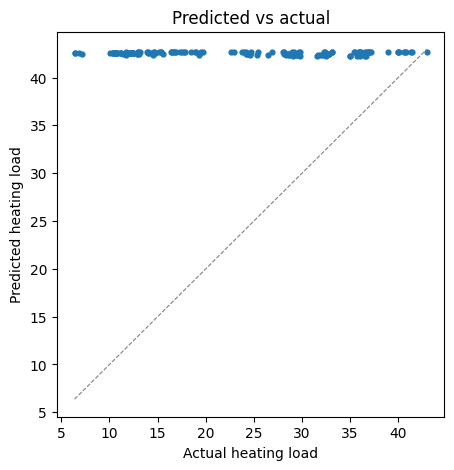

In [6]:
def plot_predicted_vs_actual(predicted, actual):
    """Each building's predicted value against its actual value; on the diagonal, a perfect prediction."""
    lo, hi = min(actual + predicted), max(actual + predicted)
    plt.figure(figsize=(5, 5))
    plt.scatter(actual, predicted, s=12)
    plt.plot([lo, hi], [lo, hi], color="gray", ls="--", lw=0.8)
    plt.xlabel("Actual heating load")
    plt.ylabel("Predicted heating load")
    plt.title("Predicted vs actual")
    plt.show()

import csv
with open("data/energy_to_predict_actual.csv", newline="") as f:
    actual = [float(row["heating_load"]) for row in csv.DictReader(f)]
with open(train_file, newline="") as f:
    training_values = [float(row["heating_load"]) for row in csv.DictReader(f)]
average = sum(training_values) / len(training_values)

errors = [abs(p - a) for p, a in zip(predicted, actual)]
baseline = [abs(average - a) for a in actual]
print(f"Mean absolute error: {sum(errors) / len(errors):.2f}")
print(f"Always predicting the training average ({average:.1f}): {sum(baseline) / len(baseline):.2f}")

print("\nThe first 10:")
print(f"  {'Sample':>6}  {'Predicted':>9}  {'Actual':>7}  {'Error':>6}")
for i, (p, a) in enumerate(zip(predicted[:10], actual[:10]), start=1):
    print(f"  {i:>6}  {p:9.2f}  {a:7.2f}  {abs(p - a):6.2f}")
plot_predicted_vs_actual(predicted, actual)

## Next steps

- `01_quick_start.ipynb`: the same steps for classification, and explainable AI (which works with classification models only)
- The regression settings (`num_qubits_target`, `loss_type`) in the User Guide: [Regression](https://coherent-computing.github.io/redcedar/user_guide/#regression)
- `04_training_in_depth.ipynb`: training loss during training, layers, reusing models